# PODNN from precomputed FOM data

This notebook implements the PODNN method using the
precomputed FOM snapshots.

The POD basis is constructed consistently with the
POD-Galerkin implementation.

The workflow is:

1. FEM environment setup
2. Load precomputed FOM snapshots
3. Construct velocity, supremizer and pressure POD bases
4. Validate POD reconstruction
5. Train neural networks to predict POD coefficients


In [149]:
from google.colab import drive

drive.mount("/content/drive")

PROJECT_DIR = "/content/drive/MyDrive/ColabNotebooks/MOR-Project"

%cd $PROJECT_DIR

!pip install -r requirements.txt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ColabNotebooks/MOR-Project


In [150]:
import os
import time

import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt

import sys
sys.path.insert(1, "../")

In [151]:
DATA_DIR = os.path.join(
    PROJECT_DIR,
    "data",
    "fom"
)

POD_MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models",
    "pod_galerkin"
)

print("Data directory:")
print(DATA_DIR)

print("\nPOD model directory:")
print(POD_MODEL_DIR)

assert os.path.isdir(DATA_DIR), (
    f"Missing data directory: {DATA_DIR}"
)

assert os.path.isdir(POD_MODEL_DIR), (
    f"Missing POD model directory: {POD_MODEL_DIR}"
)

print("Directories found.")

Data directory:
/content/drive/MyDrive/ColabNotebooks/MOR-Project/data/fom

POD model directory:
/content/drive/MyDrive/ColabNotebooks/MOR-Project/models/pod_galerkin
Directories found.


In [152]:
train_parameters = np.load(
    os.path.join(
        DATA_DIR,
        "train1000_parameters.npy"
    )
)

train_snapshots = np.load(
    os.path.join(
        DATA_DIR,
        "train1000_snapshots.npy"
    )
)

train_metadata = np.load(
    os.path.join(
        DATA_DIR,
        "train1000_metadata.npy"
    ),
    allow_pickle=True
)

test_parameters = np.load(
    os.path.join(
        DATA_DIR,
        "test_parameters.npy"
    )
)

test_snapshots = np.load(
    os.path.join(
        DATA_DIR,
        "test_snapshots.npy"
    )
)

test_metadata = np.load(
    os.path.join(
        DATA_DIR,
        "test_metadata.npy"
    ),
    allow_pickle=True
)

print("Training parameters :", train_parameters.shape)
print("Training snapshots  :", train_snapshots.shape)
print("Test parameters     :", test_parameters.shape)
print("Test snapshots      :", test_snapshots.shape)

Training parameters : (1000, 2)
Training snapshots  : (1000, 6761)
Test parameters     : (50, 2)
Test snapshots      : (50, 6761)


In [153]:
pod_model = np.load(
    os.path.join(
        POD_MODEL_DIR,
        "pod_galerkin_model.npz"
    )
)

V_u = pod_model["V_u"]
V_s = pod_model["V_s"]
V_p = pod_model["V_p"]

B_pg = pod_model["B"]

N_u = int(pod_model["N_u"])
N_s = int(pod_model["N_s"])
N_p = int(pod_model["N_p"])

eig_u = pod_model["eig_u"]
eig_s = pod_model["eig_s"]
eig_p = pod_model["eig_p"]

energy_u = pod_model["energy_u"]
energy_s = pod_model["energy_s"]
energy_p = pod_model["energy_p"]

inner_product_u = scipy.sparse.load_npz(
    os.path.join(
        POD_MODEL_DIR,
        "inner_product_u.npz"
    )
)

print("V_u:", V_u.shape)
print("V_s:", V_s.shape)
print("V_p:", V_p.shape)
print("B_pg:", B_pg.shape)

print()

print("N_u:", N_u)
print("N_s:", N_s)
print("N_p:", N_p)

print()

print("inner_product_u:", inner_product_u.shape)

V_u: (5932, 20)
V_s: (5932, 20)
V_p: (829, 20)
B_pg: (6761, 60)

N_u: 20
N_s: 20
N_p: 20

inner_product_u: (5932, 5932)


In [154]:
tot_dofs = train_snapshots.shape[1]

B_nn = np.zeros(
    (tot_dofs, N_u + N_p)
)

speed_dofs = V_u.shape[0]

B_nn[
    :speed_dofs,
    :N_u
] = V_u

B_nn[
    speed_dofs:,
    N_u:
] = V_p

print("B_nn:", B_nn.shape)

assert B_nn.shape == (
    tot_dofs,
    N_u + N_p
)

B_nn: (6761, 40)


In [155]:
speed_block_size = V_u.shape[0]
pressure_block_size = V_p.shape[0]

assert (
    speed_block_size + pressure_block_size
    == tot_dofs
)

print("Velocity block :", speed_block_size)
print("Pressure block:", pressure_block_size)
print("Total          :", tot_dofs)

train_u = train_snapshots[
    :, :speed_block_size
]

train_p = train_snapshots[
    :, speed_block_size:
]

test_u = test_snapshots[
    :, :speed_block_size
]

test_p = test_snapshots[
    :, speed_block_size:
]

print("train_u:", train_u.shape)
print("train_p:", train_p.shape)

print("test_u :", test_u.shape)
print("test_p :", test_p.shape)

Velocity block : 5932
Pressure block: 829
Total          : 6761
train_u: (1000, 5932)
train_p: (1000, 829)
test_u : (50, 5932)
test_p : (50, 829)


In [156]:
def project_velocity(
    velocity,
    V_u,
    inner_product_u
):
    return V_u.T @ (
        inner_product_u @ velocity
    )


def project_pressure(
    pressure,
    V_p
):
    return V_p.T @ pressure

def reconstruct_velocity(
    coefficients,
    V_u
):
    return V_u @ coefficients


def reconstruct_pressure(
    coefficients,
    V_p
):
    return V_p @ coefficients


i = 0

u_fom = train_u[i]
p_fom = train_p[i]

a_u = project_velocity(
    u_fom,
    V_u,
    inner_product_u
)

a_p = project_pressure(
    p_fom,
    V_p
)

u_pod = reconstruct_velocity(
    a_u,
    V_u
)

p_pod = reconstruct_pressure(
    a_p,
    V_p
)

print("a_u:", a_u.shape)
print("a_p:", a_p.shape)

assert a_u.shape == (N_u,)
assert a_p.shape == (N_p,)

a_u: (20,)
a_p: (20,)


In [157]:
def relative_velocity_error(
    reference,
    approximation,
    inner_product_u
):

    error = reference - approximation

    numerator = np.sqrt(
        error @ (
            inner_product_u @ error
        )
    )

    denominator = np.sqrt(
        reference @ (
            inner_product_u @ reference
        )
    )

    return numerator / denominator


def relative_pressure_error(
    reference,
    approximation
):

    return (
        np.linalg.norm(reference - approximation)
        / np.linalg.norm(reference)
    )

In [158]:
pod_train_errors_u = []
pod_train_errors_p = []

for i in range(len(train_snapshots)):

    u_fom = train_u[i]
    p_fom = train_p[i]

    a_u = project_velocity(
        u_fom,
        V_u,
        inner_product_u
    )

    a_p = project_pressure(
        p_fom,
        V_p
    )

    u_pod = reconstruct_velocity(
        a_u,
        V_u
    )

    p_pod = reconstruct_pressure(
        a_p,
        V_p
    )

    pod_train_errors_u.append(
        relative_velocity_error(
            u_fom,
            u_pod,
            inner_product_u
        )
    )

    pod_train_errors_p.append(
        relative_pressure_error(
            p_fom,
            p_pod
        )
    )

pod_train_errors_u = np.asarray(
    pod_train_errors_u
)

pod_train_errors_p = np.asarray(
    pod_train_errors_p
)

In [159]:
pod_test_errors_u = []
pod_test_errors_p = []

for i in range(len(test_snapshots)):

    u_fom = test_u[i]
    p_fom = test_p[i]

    a_u = project_velocity(
        u_fom,
        V_u,
        inner_product_u
    )

    a_p = project_pressure(
        p_fom,
        V_p
    )

    u_pod = reconstruct_velocity(
        a_u,
        V_u
    )

    p_pod = reconstruct_pressure(
        a_p,
        V_p
    )

    pod_test_errors_u.append(
        relative_velocity_error(
            u_fom,
            u_pod,
            inner_product_u
        )
    )

    pod_test_errors_p.append(
        relative_pressure_error(
            p_fom,
            p_pod
        )
    )

pod_test_errors_u = np.asarray(
    pod_test_errors_u
)

pod_test_errors_p = np.asarray(
    pod_test_errors_p
)

In [160]:
print("=" * 65)
print("POD BASIS VALIDATION")
print("=" * 65)

print()
print("POD dimensions")
print("-" * 65)

print("Velocity modes   :", N_u)
print("Supremizer modes :", N_s)
print("Pressure modes   :", N_p)

print()
print("Training set")
print("-" * 65)

print(
    f"Velocity mean error : "
    f"{pod_train_errors_u.mean():.6e}"
)

print(
    f"Velocity max error  : "
    f"{pod_train_errors_u.max():.6e}"
)

print(
    f"Pressure mean error : "
    f"{pod_train_errors_p.mean():.6e}"
)

print(
    f"Pressure max error  : "
    f"{pod_train_errors_p.max():.6e}"
)

print()
print("Test set")
print("-" * 65)

print(
    f"Velocity mean error : "
    f"{pod_test_errors_u.mean():.6e}"
)

print(
    f"Velocity max error  : "
    f"{pod_test_errors_u.max():.6e}"
)

print(
    f"Pressure mean error : "
    f"{pod_test_errors_p.mean():.6e}"
)

print(
    f"Pressure max error  : "
    f"{pod_test_errors_p.max():.6e}"
)

POD BASIS VALIDATION

POD dimensions
-----------------------------------------------------------------
Velocity modes   : 20
Supremizer modes : 20
Pressure modes   : 20

Training set
-----------------------------------------------------------------
Velocity mean error : 1.226098e-03
Velocity max error  : 1.137770e-01
Pressure mean error : 4.899329e-03
Pressure max error  : 5.214418e-01

Test set
-----------------------------------------------------------------
Velocity mean error : 1.026341e-03
Velocity max error  : 9.399935e-03
Pressure mean error : 5.549383e-03
Pressure max error  : 1.597744e-01


In [161]:
def compute_velocity_coefficients(
    velocity_snapshots,
    V_u,
    inner_product_u
):
    """
    Project velocity snapshots onto the POD velocity basis.

    Parameters
    ----------
    velocity_snapshots : ndarray
        Shape (N_snapshots, N_velocity_dofs)

    V_u : ndarray
        Velocity POD basis.
        Shape (N_velocity_dofs, N_u)

    inner_product_u : scipy sparse matrix
        Velocity inner-product matrix.

    Returns
    -------
    coefficients : ndarray
        Shape (N_snapshots, N_u)
    """

    coefficients = (
        velocity_snapshots
        @ inner_product_u
        @ V_u
    )

    return np.asarray(coefficients)


def compute_pressure_coefficients(
    pressure_snapshots,
    V_p
):
    """
    Project pressure snapshots onto the POD pressure basis.

    Parameters
    ----------
    pressure_snapshots : ndarray
        Shape (N_snapshots, N_pressure_dofs)

    V_p : ndarray
        Pressure POD basis.
        Shape (N_pressure_dofs, N_p)

    Returns
    -------
    coefficients : ndarray
        Shape (N_snapshots, N_p)
    """

    coefficients = (
        pressure_snapshots @ V_p
    )

    return np.asarray(coefficients)

In [162]:
coeff_u_train = compute_velocity_coefficients(
    train_u,
    V_u,
    inner_product_u
)

coeff_p_train = compute_pressure_coefficients(
    train_p,
    V_p
)

print("Velocity target shape :", coeff_u_train.shape)
print("Pressure target shape :", coeff_p_train.shape)

assert coeff_u_train.shape == (
    len(train_snapshots),
    N_u
)

assert coeff_p_train.shape == (
    len(train_snapshots),
    N_p
)

coeff_u_test = compute_velocity_coefficients(
    test_u,
    V_u,
    inner_product_u
)

coeff_p_test = compute_pressure_coefficients(
    test_p,
    V_p
)

print("Velocity test target shape :", coeff_u_test.shape)
print("Pressure test target shape :", coeff_p_test.shape)

Velocity target shape : (1000, 20)
Pressure target shape : (1000, 20)
Velocity test target shape : (50, 20)
Pressure test target shape : (50, 20)


In [163]:
i = 0

u_from_coeff = (
    V_u @ coeff_u_train[i]
)

p_from_coeff = (
    V_p @ coeff_p_train[i]
)

error_u = relative_velocity_error(
    train_u[i],
    u_from_coeff,
    inner_product_u
)

error_p = relative_pressure_error(
    train_p[i],
    p_from_coeff
)

print(f"Velocity reconstruction error : {error_u:.6e}")
print(f"Pressure reconstruction error : {error_p:.6e}")

Velocity reconstruction error : 4.102523e-04
Pressure reconstruction error : 1.126020e-03


In [164]:
reconstructed_u_train = (
    coeff_u_train @ V_u.T
)

reconstructed_p_train = (
    coeff_p_train @ V_p.T
)

print(
    "Velocity reconstruction shape:",
    reconstructed_u_train.shape
)

print(
    "Pressure reconstruction shape:",
    reconstructed_p_train.shape
)

errors_u_check = np.zeros(len(train_snapshots))
errors_p_check = np.zeros(len(train_snapshots))

for i in range(len(train_snapshots)):

    errors_u_check[i] = relative_velocity_error(
        train_u[i],
        reconstructed_u_train[i],
        inner_product_u
    )

    errors_p_check[i] = relative_pressure_error(
        train_p[i],
        reconstructed_p_train[i]
    )

print(
    "Maximum velocity error:",
    errors_u_check.max()
)

print(
    "Maximum pressure error:",
    errors_p_check.max()
)

Velocity reconstruction shape: (1000, 5932)
Pressure reconstruction shape: (1000, 829)
Maximum velocity error: 0.1137769747520169
Maximum pressure error: 0.5214418409601723


In [165]:
print("Velocity coefficients")
print("--------------------")
print(
    "min:",
    coeff_u_train.min()
)

print(
    "max:",
    coeff_u_train.max()
)

print(
    "mean:",
    coeff_u_train.mean()
)

print(
    "std:",
    coeff_u_train.std()
)

print()

print("Pressure coefficients")
print("--------------------")
print(
    "min:",
    coeff_p_train.min()
)

print(
    "max:",
    coeff_p_train.max()
)

print(
    "mean:",
    coeff_p_train.mean()
)

print(
    "std:",
    coeff_p_train.std()
)

u_coeff_mean = coeff_u_train.mean(axis=0)
u_coeff_std = coeff_u_train.std(axis=0)

p_coeff_mean = coeff_p_train.mean(axis=0)
p_coeff_std = coeff_p_train.std(axis=0)

print(
    f"{'Mode':>6} "
    f"{'u mean':>14} "
    f"{'u std':>14} "
    f"{'p mean':>14} "
    f"{'p std':>14}"
)

print("-" * 68)

for k in range(min(N_u, N_p)):

    print(
        f"{k+1:6d} "
        f"{u_coeff_mean[k]:14.6e} "
        f"{u_coeff_std[k]:14.6e} "
        f"{p_coeff_mean[k]:14.6e} "
        f"{p_coeff_std[k]:14.6e}"
    )

Velocity coefficients
--------------------
min: -8.12004687209785
max: 15.478831724747357
mean: 0.0005418150206388346
std: 0.3873526517967922

Pressure coefficients
--------------------
min: -81.960579133861
max: 43.76623659791512
mean: -1.3298540098652718
std: 12.088270946737552
  Mode         u mean          u std         p mean          p std
--------------------------------------------------------------------
     1   1.934491e-01   8.632134e-01  -1.998464e+01   2.496880e+01
     2   1.380005e-01   7.932548e-01  -3.992025e+00   2.338150e+01
     3  -2.216278e-02   6.022484e-01  -5.730322e-01   1.984450e+01
     4  -2.410594e-01   5.801623e-01   3.597200e+00   1.694935e+01
     5  -8.332317e-02   5.033058e-01  -5.795331e+00   1.394503e+01
     6   2.543263e-02   4.071917e-01  -9.604359e-01   1.234748e+01
     7   1.338092e-02   2.781204e-01  -3.885050e+00   1.045166e+01
     8  -2.528227e-03   3.341062e-01   1.486670e+00   7.642170e+00
     9  -2.834556e-02   3.063923e-01   2.860572

In [166]:
print("=" * 65)
print("PODNN TARGET DATASET")
print("=" * 65)

print()
print("Inputs")
print("-" * 65)
print("Training parameters :", train_parameters.shape)
print("Test parameters     :", test_parameters.shape)

print()
print("Targets")
print("-" * 65)
print("Velocity train      :", coeff_u_train.shape)
print("Pressure train      :", coeff_p_train.shape)
print("Velocity test       :", coeff_u_test.shape)
print("Pressure test       :", coeff_p_test.shape)

print()
print("POD dimensions")
print("-" * 65)
print("N_u =", N_u)
print("N_p =", N_p)

print()
print("Saved to")
print("-" * 65)
# print(TARGET_DIR)

PODNN TARGET DATASET

Inputs
-----------------------------------------------------------------
Training parameters : (1000, 2)
Test parameters     : (50, 2)

Targets
-----------------------------------------------------------------
Velocity train      : (1000, 20)
Pressure train      : (1000, 20)
Velocity test       : (50, 20)
Pressure test       : (50, 20)

POD dimensions
-----------------------------------------------------------------
N_u = 20
N_p = 20

Saved to
-----------------------------------------------------------------


In [167]:
x_mean = train_parameters.mean(axis=0)
x_std = train_parameters.std(axis=0)

print("Parameter mean:", x_mean)
print("Parameter std :", x_std)

x_train = (
    train_parameters - x_mean
) / x_std

x_test = (
    test_parameters - x_mean
) / x_std

print("Training input mean:", x_train.mean(axis=0))
print("Training input std :", x_train.std(axis=0))

print()
print("Test input mean:", x_test.mean(axis=0))
print("Test input std :", x_test.std(axis=0))

Parameter mean: [5.20521691 2.00954541]
Parameter std : [2.83137945 0.58223899]
Training input mean: [2.38409292e-15 5.70210545e-15]
Training input std : [1. 1.]

Test input mean: [0.07394843 0.05227668]
Test input std : [0.99290847 1.04903259]


In [168]:
u_mean = coeff_u_train.mean(axis=0)
u_std = coeff_u_train.std(axis=0)

EPS = 1e-12

u_std = np.maximum(
    u_std,
    EPS
)

y_u_train = (
    coeff_u_train - u_mean
) / u_std

y_u_test = (
    coeff_u_test - u_mean
) / u_std

p_mean = coeff_p_train.mean(axis=0)
p_std = coeff_p_train.std(axis=0)

p_std = np.maximum(
    p_std,
    EPS
)

y_p_train = (
    coeff_p_train - p_mean
) / p_std

y_p_test = (
    coeff_p_test - p_mean
) / p_std

In [169]:
print("Velocity target statistics")
print("-" * 60)

print(
    "Mean of normalized training targets:",
    y_u_train.mean(axis=0)
)

print(
    "Std of normalized training targets:",
    y_u_train.std(axis=0)
)

print()
print("Pressure target statistics")
print("-" * 60)

print(
    "Mean of normalized training targets:",
    y_p_train.mean(axis=0)
)

print(
    "Std of normalized training targets:",
    y_p_train.std(axis=0)
)

print("Normalized velocity targets:")
print(
    "min =", y_u_train.min(),
    "max =", y_u_train.max()
)

print()

print("Normalized pressure targets:")
print(
    "min =", y_p_train.min(),
    "max =", y_p_train.max()
)

coeff_u_reconstructed = (
    y_u_train * u_std
    + u_mean
)

print(
    "Velocity denormalization error:",
    np.max(
        np.abs(
            coeff_u_reconstructed
            - coeff_u_train
        )
    )
)

coeff_p_reconstructed = (
    y_p_train * p_std
    + p_mean
)

print(
    "Pressure denormalization error:",
    np.max(
        np.abs(
            coeff_p_reconstructed
            - coeff_p_train
        )
    )
)

print("Smallest velocity coefficient std:",
      u_std.min())

print("Smallest pressure coefficient std:",
      p_std.min())

Velocity target statistics
------------------------------------------------------------
Mean of normalized training targets: [-2.30371278e-17 -1.19931842e-16 -1.08801856e-17 -8.45989945e-17
  3.91908728e-17  2.67980083e-17  6.89726054e-18 -1.71676909e-17
  1.92068583e-17 -5.44009282e-17  5.67601521e-18 -1.08413278e-16
 -9.89763826e-17 -1.12842027e-16 -7.98527910e-17 -4.31876757e-17
  5.80646642e-17 -4.36248260e-17  1.39471767e-17  2.13856710e-17]
Std of normalized training targets: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Pressure target statistics
------------------------------------------------------------
Mean of normalized training targets: [-4.79949414e-16  8.06577027e-17 -1.94844141e-17  2.74792342e-16
 -6.72462086e-16 -1.70197190e-16 -3.33066907e-17  2.72004641e-18
 -3.74696801e-16 -9.27036226e-17 -1.94400052e-16 -1.55431223e-17
  1.04583009e-16 -2.37587727e-17  1.64313008e-17 -4.32986980e-18
  4.01345623e-17  1.80966353e-17  1.96787031e-17  1.11022302e-18]

In [170]:
import torch

torch.manual_seed(31)

x_train_t = torch.tensor(
    x_train,
    dtype=torch.float32
)

x_test_t = torch.tensor(
    x_test,
    dtype=torch.float32
)

y_u_train_t = torch.tensor(
    y_u_train,
    dtype=torch.float32
)

y_u_test_t = torch.tensor(
    y_u_test,
    dtype=torch.float32
)

y_p_train_t = torch.tensor(
    y_p_train,
    dtype=torch.float32
)

y_p_test_t = torch.tensor(
    y_p_test,
    dtype=torch.float32
)

print("x_train :", x_train_t.shape)
print("x_test  :", x_test_t.shape)

print("y_u_train:", y_u_train_t.shape)
print("y_p_train:", y_p_train_t.shape)

normalization = {
    "x_mean": x_mean,
    "x_std": x_std,
    "u_mean": u_mean,
    "u_std": u_std,
    "p_mean": p_mean,
    "p_std": p_std,
}

x_train : torch.Size([1000, 2])
x_test  : torch.Size([50, 2])
y_u_train: torch.Size([1000, 20])
y_p_train: torch.Size([1000, 20])


In [171]:
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(31)

print("PyTorch version:", torch.__version__)

PyTorch version: 2.11.0+cpu


In [172]:
class Net(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        hidden_layers=3,
        nodes=64
    ):
        super().__init__()

        layers = [
            nn.Linear(input_dim, nodes),
            nn.Tanh()
        ]

        for _ in range(hidden_layers - 1):
            layers += [
                nn.Linear(nodes, nodes),
                nn.Tanh()
            ]

        # Linear output layer
        layers += [
            nn.Linear(nodes, output_dim)
        ]

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

net_u = Net(
    input_dim=2,
    output_dim=N_u,
    hidden_layers=3,
    nodes=64
)

net_p = Net(
    input_dim=2,
    output_dim=N_p,
    hidden_layers=3,
    nodes=64
)

print("Velocity network")
print(net_u)

print("\nPressure network")
print(net_p)

Velocity network
Net(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=20, bias=True)
  )
)

Pressure network
Net(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): Tanh()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): Tanh()
    (6): Linear(in_features=64, out_features=20, bias=True)
  )
)


In [173]:
print("Input shape :", x_train_t.shape)
print("Velocity target shape :", y_u_train_t.shape)
print("Pressure target shape :", y_p_train_t.shape)

assert x_train_t.shape == (len(train_parameters), 2)
assert y_u_train_t.shape == (len(train_parameters), N_u)
assert y_p_train_t.shape == (len(train_parameters), N_p)

with torch.no_grad():

    test_output_u = net_u(x_train_t[:5])
    test_output_p = net_p(x_train_t[:5])

print("Velocity output:", test_output_u.shape)
print("Pressure output:", test_output_p.shape)

Input shape : torch.Size([1000, 2])
Velocity target shape : torch.Size([1000, 20])
Pressure target shape : torch.Size([1000, 20])
Velocity output: torch.Size([5, 20])
Pressure output: torch.Size([5, 20])


In [174]:
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
N_EPOCHS = 50000

loss_fn = nn.MSELoss()

optimizer_u = optim.Adam(
    net_u.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

optimizer_p = optim.Adam(
    net_p.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

def train_network(
    net,
    x_train,
    y_train,
    optimizer,
    loss_fn,
    n_epochs
):

    train_losses = []

    for epoch in range(1, n_epochs + 1):

        net.train()

        optimizer.zero_grad()

        prediction = net(x_train)

        loss = loss_fn(
            prediction,
            y_train
        )

        loss.backward()

        optimizer.step()

        train_losses.append(
            loss.item()
        )

        if epoch == 1 or epoch % 250 == 0:
            print(
                f"Epoch {epoch:5d} | "
                f"Loss = {loss.item():.6e}"
            )

    return np.asarray(train_losses)

In [175]:
print("=" * 65)
print("TRAINING VELOCITY NETWORK")
print("=" * 65)

start_time = time.perf_counter()

losses_u = train_network(
    net_u,
    x_train_t,
    y_u_train_t,
    optimizer_u,
    loss_fn,
    N_EPOCHS
)

training_time_u = (
    time.perf_counter() - start_time
)

print()
print(
    f"Velocity training time: "
    f"{training_time_u:.2f} s"
)

TRAINING VELOCITY NETWORK
Epoch     1 | Loss = 1.018212e+00
Epoch   250 | Loss = 4.831676e-01
Epoch   500 | Loss = 1.799026e-01
Epoch   750 | Loss = 8.733958e-02
Epoch  1000 | Loss = 4.926358e-02
Epoch  1250 | Loss = 3.132065e-02
Epoch  1500 | Loss = 2.031343e-02
Epoch  1750 | Loss = 1.399564e-02
Epoch  2000 | Loss = 1.038641e-02
Epoch  2250 | Loss = 8.114714e-03
Epoch  2500 | Loss = 6.589308e-03
Epoch  2750 | Loss = 5.391681e-03
Epoch  3000 | Loss = 4.572995e-03
Epoch  3250 | Loss = 3.992232e-03
Epoch  3500 | Loss = 3.557939e-03
Epoch  3750 | Loss = 3.199243e-03
Epoch  4000 | Loss = 2.920194e-03
Epoch  4250 | Loss = 2.681745e-03
Epoch  4500 | Loss = 2.478999e-03
Epoch  4750 | Loss = 2.310905e-03
Epoch  5000 | Loss = 2.161239e-03
Epoch  5250 | Loss = 2.030203e-03
Epoch  5500 | Loss = 1.944828e-03
Epoch  5750 | Loss = 1.823183e-03
Epoch  6000 | Loss = 1.706024e-03
Epoch  6250 | Loss = 1.788804e-03
Epoch  6500 | Loss = 1.535150e-03
Epoch  6750 | Loss = 1.463485e-03
Epoch  7000 | Loss = 1

In [176]:
print("=" * 65)
print("TRAINING PRESSURE NETWORK")
print("=" * 65)

start_time = time.perf_counter()

losses_p = train_network(
    net_p,
    x_train_t,
    y_p_train_t,
    optimizer_p,
    loss_fn,
    N_EPOCHS
)

training_time_p = (
    time.perf_counter() - start_time
)

print()
print(
    f"Pressure training time: "
    f"{training_time_p:.2f} s"
)

TRAINING PRESSURE NETWORK
Epoch     1 | Loss = 1.009455e+00
Epoch   250 | Loss = 4.353378e-01
Epoch   500 | Loss = 8.825089e-02
Epoch   750 | Loss = 2.747689e-02
Epoch  1000 | Loss = 1.178978e-02
Epoch  1250 | Loss = 6.165150e-03
Epoch  1500 | Loss = 3.827785e-03
Epoch  1750 | Loss = 2.682053e-03
Epoch  2000 | Loss = 2.065761e-03
Epoch  2250 | Loss = 1.625023e-03
Epoch  2500 | Loss = 1.413464e-03
Epoch  2750 | Loss = 1.421469e-03
Epoch  3000 | Loss = 1.069495e-03
Epoch  3250 | Loss = 8.988117e-04
Epoch  3500 | Loss = 8.207803e-04
Epoch  3750 | Loss = 7.534930e-04
Epoch  4000 | Loss = 6.865796e-04
Epoch  4250 | Loss = 6.469947e-04
Epoch  4500 | Loss = 6.414736e-04
Epoch  4750 | Loss = 7.074756e-04
Epoch  5000 | Loss = 5.565587e-04
Epoch  5250 | Loss = 5.122491e-04
Epoch  5500 | Loss = 4.892334e-04
Epoch  5750 | Loss = 4.695115e-04
Epoch  6000 | Loss = 4.516738e-04
Epoch  6250 | Loss = 4.386845e-04
Epoch  6500 | Loss = 4.572442e-04
Epoch  6750 | Loss = 4.093443e-04
Epoch  7000 | Loss = 4

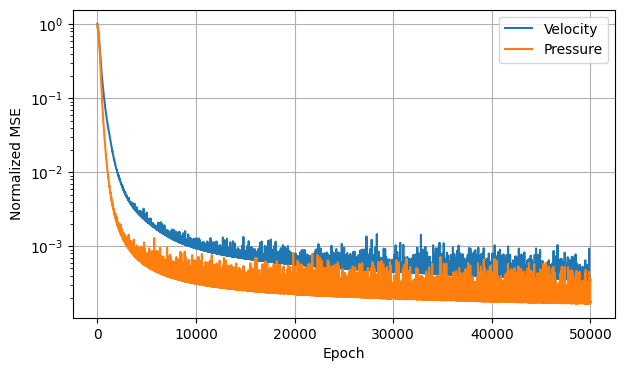

In [184]:
plt.figure(figsize=(7, 4))

plt.semilogy(
    losses_u,
    label="Velocity"
)

plt.semilogy(
    losses_p,
    label="Pressure"
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")

plt.grid(True)
plt.legend()
plt.show()

In [178]:
net_u.eval()
net_p.eval()

with torch.no_grad():

    pred_u_train = (
        net_u(x_train_t)
        .cpu()
        .numpy()
    )

    pred_p_train = (
        net_p(x_train_t)
        .cpu()
        .numpy()
    )

print("Predicted velocity coefficients:",
      pred_u_train.shape)

print("Predicted pressure coefficients:",
      pred_p_train.shape)

Predicted velocity coefficients: (1000, 20)
Predicted pressure coefficients: (1000, 20)


In [179]:
coeff_u_pred_train = (
    pred_u_train * u_std
    + u_mean
)

coeff_p_pred_train = (
    pred_p_train * p_std
    + p_mean
)

relative_coeff_error_u = (
    np.linalg.norm(
        coeff_u_pred_train - coeff_u_train
    )
    /
    np.linalg.norm(coeff_u_train)
)

relative_coeff_error_p = (
    np.linalg.norm(
        coeff_p_pred_train - coeff_p_train
    )
    /
    np.linalg.norm(coeff_p_train)
)

print(
    f"Velocity coefficient error : "
    f"{relative_coeff_error_u:.6e}"
)

print(
    f"Pressure coefficient error : "
    f"{relative_coeff_error_p:.6e}"
)

Velocity coefficient error : 1.589481e-02
Pressure coefficient error : 5.187949e-03


In [180]:
u_pred_train = (
    coeff_u_pred_train @ V_u.T
)

p_pred_train = (
    coeff_p_pred_train @ V_p.T
)

podnn_train_errors_u = np.zeros(
    len(train_snapshots)
)

podnn_train_errors_p = np.zeros(
    len(train_snapshots)
)

for i in range(len(train_snapshots)):

    podnn_train_errors_u[i] = (
        relative_velocity_error(
            train_u[i],
            u_pred_train[i],
            inner_product_u
        )
    )

    podnn_train_errors_p[i] = (
        relative_pressure_error(
            train_p[i],
            p_pred_train[i]
        )
    )

print("=" * 65)
print("PODNN TRAINING ERROR")
print("=" * 65)

print()
print(
    f"Velocity mean error : "
    f"{podnn_train_errors_u.mean():.6e}"
)

print(
    f"Velocity max error  : "
    f"{podnn_train_errors_u.max():.6e}"
)

print(
    f"Pressure mean error : "
    f"{podnn_train_errors_p.mean():.6e}"
)

print(
    f"Pressure max error  : "
    f"{podnn_train_errors_p.max():.6e}"
)

PODNN TRAINING ERROR

Velocity mean error : 3.864370e-02
Velocity max error  : 2.558994e-01
Pressure mean error : 8.414751e-03
Pressure max error  : 5.214786e-01


In [181]:
# ============================================================
# PODNN TEST EVALUATION
# ============================================================

net_u.eval()
net_p.eval()

with torch.no_grad():
    # Predict normalized POD coefficients
    pred_u_test_normalized = (
        net_u(x_test_t).cpu().numpy()
    )

    pred_p_test_normalized = (
        net_p(x_test_t).cpu().numpy()
    )

# Undo coefficient normalization
coeff_u_pred_test = (
    pred_u_test_normalized * u_std + u_mean
)

coeff_p_pred_test = (
    pred_p_test_normalized * p_std + p_mean
)

# Reconstruct physical solution
u_podnn_test = coeff_u_pred_test @ V_u.T
p_podnn_test = coeff_p_pred_test @ V_p.T

# Per-sample errors
podnn_test_errors_u = np.zeros(len(test_snapshots))
podnn_test_errors_p = np.zeros(len(test_snapshots))

coefficient_errors_u = np.zeros(len(test_snapshots))
coefficient_errors_p = np.zeros(len(test_snapshots))

for i in range(len(test_snapshots)):

    # Reduced-space errors
    coefficient_errors_u[i] = (
        np.linalg.norm(
            coeff_u_pred_test[i] - coeff_u_test[i]
        )
        / np.linalg.norm(coeff_u_test[i])
    )

    coefficient_errors_p[i] = (
        np.linalg.norm(
            coeff_p_pred_test[i] - coeff_p_test[i]
        )
        / np.linalg.norm(coeff_p_test[i])
    )

    # Physical field errors
    podnn_test_errors_u[i] = (
        relative_velocity_error(
            test_u[i],
            u_podnn_test[i],
            inner_product_u
        )
    )

    podnn_test_errors_p[i] = (
        relative_pressure_error(
            test_p[i],
            p_podnn_test[i]
        )
    )

print("=" * 70)
print("PODNN TEST EVALUATION")
print("=" * 70)

print("\nVelocity")
print("-" * 70)
print(
    f"POD   mean error : {pod_test_errors_u.mean():.6e}"
)
print(
    f"PODNN mean error : {podnn_test_errors_u.mean():.6e}"
)
print(
    f"PODNN max error  : {podnn_test_errors_u.max():.6e}"
)
print(
    f"NN coefficient error : "
    f"{coefficient_errors_u.mean():.6e}"
)

print("\nPressure")
print("-" * 70)
print(
    f"POD   mean error : {pod_test_errors_p.mean():.6e}"
)
print(
    f"PODNN mean error : {podnn_test_errors_p.mean():.6e}"
)
print(
    f"PODNN max error  : {podnn_test_errors_p.max():.6e}"
)
print(
    f"NN coefficient error : "
    f"{coefficient_errors_p.mean():.6e}"
)

PODNN TEST EVALUATION

Velocity
----------------------------------------------------------------------
POD   mean error : 1.026341e-03
PODNN mean error : 4.710279e-02
PODNN max error  : 2.362499e-01
NN coefficient error : 4.708328e-02

Pressure
----------------------------------------------------------------------
POD   mean error : 5.549383e-03
PODNN mean error : 1.136729e-02
PODNN max error  : 2.520330e-01
NN coefficient error : 9.438842e-03


In [185]:
print("=" * 70)
print("PODNN TEST EVALUATION")
print("=" * 70)

print("\nVelocity")
print("-" * 70)

print(
    f"PODNN mean error       : {podnn_test_errors_u.mean():.6e}"
)
print(
    f"PODNN median error     : {np.median(podnn_test_errors_u):.6e}"
)
print(
    f"PODNN 95th percentile  : {np.percentile(podnn_test_errors_u, 95):.6e}"
)
print(
    f"PODNN max error        : {podnn_test_errors_u.max():.6e}"
)
print(
    f"NN coefficient error   : {coefficient_errors_u.mean():.6e}"
)

print("\nPressure")
print("-" * 70)

print(
    f"PODNN mean error       : {podnn_test_errors_p.mean():.6e}"
)
print(
    f"PODNN median error     : {np.median(podnn_test_errors_p):.6e}"
)
print(
    f"PODNN 95th percentile  : {np.percentile(podnn_test_errors_p, 95):.6e}"
)
print(
    f"PODNN max error        : {podnn_test_errors_p.max():.6e}"
)
print(
    f"NN coefficient error   : {coefficient_errors_p.mean():.6e}"
)

PODNN TEST EVALUATION

Velocity
----------------------------------------------------------------------
PODNN mean error       : 4.710279e-02
PODNN median error     : 3.471154e-02
PODNN 95th percentile  : 8.532384e-02
PODNN max error        : 2.362499e-01
NN coefficient error   : 4.708328e-02

Pressure
----------------------------------------------------------------------
PODNN mean error       : 1.136729e-02
PODNN median error     : 5.270409e-03
PODNN 95th percentile  : 1.566028e-02
PODNN max error        : 2.520330e-01
NN coefficient error   : 9.438842e-03


In [182]:
# ============================================================
# PODNN ONLINE SOLVER + TIMING
# ============================================================

def solve_PODNN(
    mu,
    net_u,
    net_p,
    V_u,
    V_p,
    x_mean,
    x_std,
    u_mean,
    u_std,
    p_mean,
    p_std
):
    """
    Online PODNN evaluation for one parameter vector mu=[mu0, mu1].
    Returns the full FE coefficient vector [u_x, u_y, p].
    """

    mu = np.asarray(mu, dtype=np.float32).reshape(1, 2)

    # Normalize input
    x = (mu - x_mean) / x_std
    x_t = torch.tensor(x, dtype=torch.float32)

    with torch.no_grad():

        # Predict normalized reduced coefficients
        a_u_norm = net_u(x_t).cpu().numpy()[0]
        a_p_norm = net_p(x_t).cpu().numpy()[0]

    # Undo target normalization
    a_u = a_u_norm * u_std + u_mean
    a_p = a_p_norm * p_std + p_mean

    # Reconstruct full FE vectors
    u = V_u @ a_u
    p = V_p @ a_p

    return np.concatenate([u, p])


# ------------------------------------------------------------
# Correctness check
# ------------------------------------------------------------

i = 0

solution = solve_PODNN(
    test_parameters[i],
    net_u,
    net_p,
    V_u,
    V_p,
    x_mean,
    x_std,
    u_mean,
    u_std,
    p_mean,
    p_std
)

print("Online PODNN solution shape:", solution.shape)
print("Expected shape             :", test_snapshots[i].shape)


# ------------------------------------------------------------
# Timing
# ------------------------------------------------------------

# Warm-up
for _ in range(20):
    solve_PODNN(
        test_parameters[0],
        net_u,
        net_p,
        V_u,
        V_p,
        x_mean,
        x_std,
        u_mean,
        u_std,
        p_mean,
        p_std
    )

N_TIMING = 100

times = []

for i in range(N_TIMING):

    mu = test_parameters[i % len(test_parameters)]

    t0 = time.perf_counter()

    solve_PODNN(
        mu,
        net_u,
        net_p,
        V_u,
        V_p,
        x_mean,
        x_std,
        u_mean,
        u_std,
        p_mean,
        p_std
    )

    times.append(
        time.perf_counter() - t0
    )

times = np.asarray(times)

podnn_online_mean = times.mean()
podnn_online_median = np.median(times)
podnn_online_min = times.min()

print()
print("=" * 70)
print("PODNN ONLINE COST")
print("=" * 70)

print(
    f"Mean time   : {podnn_online_mean:.6e} s"
)

print(
    f"Median time : {podnn_online_median:.6e} s"
)

print(
    f"Minimum time: {podnn_online_min:.6e} s"
)

Online PODNN solution shape: (6761,)
Expected shape             : (6761,)

PODNN ONLINE COST
Mean time   : 5.296647e-04 s
Median time : 3.989210e-04 s
Minimum time: 3.672750e-04 s


In [183]:
# ============================================================
# FINAL PODNN SUMMARY
# ============================================================

print("=" * 70)
print("PODNN SUMMARY")
print("=" * 70)

print("\nAccuracy on 50 unseen test parameters")
print("-" * 70)

print(
    f"{'':20s}"
    f"{'POD':>15s}"
    f"{'PODNN':>15s}"
)

print(
    f"{'Velocity mean':20s}"
    f"{pod_test_errors_u.mean():15.6e}"
    f"{podnn_test_errors_u.mean():15.6e}"
)

print(
    f"{'Velocity max':20s}"
    f"{pod_test_errors_u.max():15.6e}"
    f"{podnn_test_errors_u.max():15.6e}"
)

print(
    f"{'Pressure mean':20s}"
    f"{pod_test_errors_p.mean():15.6e}"
    f"{podnn_test_errors_p.mean():15.6e}"
)

print(
    f"{'Pressure max':20s}"
    f"{pod_test_errors_p.max():15.6e}"
    f"{podnn_test_errors_p.max():15.6e}"
)

print("\nPODNN online cost")
print("-" * 70)

print(
    f"Median online time : "
    f"{podnn_online_median:.6e} s"
)

print(
    f"Mean online time   : "
    f"{podnn_online_mean:.6e} s"
)

# ------------------------------------------------------------
# Optional: insert FOM timing here
# ------------------------------------------------------------

# Example structure:
#
# fom_times = []
#
# for i in range(20):
#     t0 = time.perf_counter()
#     U_fom = solve_FOM(test_parameters[i])
#     fom_times.append(time.perf_counter() - t0)
#
# fom_median = np.median(fom_times)
#
# print(f"FOM median time    : {fom_median:.6e} s")
# print(
#     f"Speed-up           : "
#     f"{fom_median / podnn_online_median:.2f}x"
# )

PODNN SUMMARY

Accuracy on 50 unseen test parameters
----------------------------------------------------------------------
                                POD          PODNN
Velocity mean          1.026341e-03   4.710279e-02
Velocity max           9.399935e-03   2.362499e-01
Pressure mean          5.549383e-03   1.136729e-02
Pressure max           1.597744e-01   2.520330e-01

PODNN online cost
----------------------------------------------------------------------
Median online time : 3.989210e-04 s
Mean online time   : 5.296647e-04 s
